In [1]:
import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
!nvidia-smi

Fri Jul  3 13:26:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.04             Driver Version: 580.159.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import os
import glob

data_dir = "/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m"
patient_dirs = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
print(f"共有 {len(patient_dirs)} 个病人")
sample_patient = patient_dirs[0]
sample_files = glob.glob(os.path.join(data_dir, sample_patient, "*.tif"))
print(f"示例病人 {sample_patient} 下有 {len(sample_files)} 张图像")
# Note on File. Refer to the archived source for the detailed original comment.
print(sample_files[:5])

共有 110 个病人
示例病人 TCGA_DU_7010_19860307 下有 116 张图像
['/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_45.tif', '/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_56_mask.tif', '/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_57.tif', '/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_33.tif', '/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_27.tif']


In [4]:
!pip install torch==2.9.* torchvision --index-url https://download.pytorch.org/whl/cu128
!pip install ipykernel==7.* matplotlib==3.*
!pip install scipy==1.17.* numpy==2.3.* scikit-image==0.26.* tensorboard==2.20.* tqdm==4.* -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://download.pytorch.org/whl/cu128
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.7/124.7 MB 122.7 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of torchvision to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 900.9/900.9 MB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.5/170.5 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 91.2 MB/s eta 0:00:00
  Attempting uninstall: triton
    Found existing installation: triton 3.6.0
    Uninstalling triton-3.6.0:
      Successfully uninstalled triton-3.6.0
  Attempting uninstall: nvidia-nvshmem-cu12
    Found existing installation: nvidia-nvshmem-cu12 3.4.5
    Uninstalling nvidia-nvshmem-cu12-3.4.5:
      Successfully uninstalled nvidia-nvshmem-cu12-3.4.5
  Attempting uninstall: torch
    Found existing installation: torch 2.10.0+cu128
    Uninstalling torch-2.10.0+cu128:


In [5]:
%%writefile dataset.py
import os
import pathlib
import itertools
import typing
import random

import numpy as np
import numpy.typing as npt
import torch
import skimage.io
import torch.utils.data

from transform import apply_affine_transform, get_random_affine_matrix_inv


class BrainSegmentationDataset(torch.utils.data.Dataset):
    in_channels = 3
    out_channels = 1

    def __init__(
        self,
        images_dir: str | pathlib.Path,
        is_train: bool = True,
        validation_cases: int = 10,
    ):
        self.is_train = is_train

        images_dir = pathlib.Path(images_dir)

        all_scan_img_paths = [scan_img_path for scan_img_path in images_dir.rglob('*.tif')
            if not scan_img_path.stem.endswith('_mask')]
        all_scan_img_paths = sorted(all_scan_img_paths, key=
            lambda scan_img_path: (scan_img_path.parent.name, int(scan_img_path.stem.rsplit('_', maxsplit=1)[1])))
        assert len(all_scan_img_paths) > 0, f'No images found in {images_dir}'

        all_patient_to_scan_img_paths = {patient: list(scan_img_paths)
            for patient, scan_img_paths in
                itertools.groupby(all_scan_img_paths, key=lambda scan_img_path: scan_img_path.parent.name)}

        self.patients = list(all_patient_to_scan_img_paths.keys())

        # select train/validation subset
        random.seed(42)
        validation_patients = sorted(random.sample(self.patients, k=validation_cases))
        if is_train:
            self.patients = sorted(set(self.patients).difference(validation_patients))
        else:
            self.patients = validation_patients

        # read images
        subset_name = 'train' if is_train else 'validation'
        # print(f'Reading {subset_name} set images ...')
        print(f'Reading {sum(len(all_patient_to_scan_img_paths[patient]) for patient in self.patients)} images from {subset_name} set ...')
        self.patient_scans_float32: list[npt.NDArray[np.float32]] = []
        self.patient_masks_float32: list[npt.NDArray[np.float32]] = []
        for patient in self.patients:
            scans_uint8: list[npt.NDArray[np.uint8]] = []
            masks_uint8: list[npt.NDArray[np.uint8]] = []
            for scan_img_path in all_patient_to_scan_img_paths[patient]:
                scans_uint8.append(skimage.io.imread(scan_img_path))
                masks_uint8.append(skimage.io.imread(scan_img_path.with_stem(scan_img_path.stem + '_mask'), as_gray=True)[..., np.newaxis])

            self.patient_scans_float32.append((np.stack(scans_uint8) / 255).astype(np.float32))   # (n_img, 256, 256, 3)
            self.patient_masks_float32.append((np.stack(masks_uint8) / 255).astype(np.float32))   # (n_img, 256, 256, 1)

        # probabilities for sampling slices based on masks
        self.slice_weights = [np.sum(masks_float32, axis=(-1, -2, -3)) for masks_float32 in self.patient_masks_float32]
        self.slice_weights = [(s + (s.sum() * 0.1 / len(s))) / (s.sum() * 1.1) for s in self.slice_weights]

        # create global index for patient and slice (idx -> (p_idx, s_idx))
        self.patient_n_imgs = [scans_float32.shape[0] for scans_float32 in self.patient_scans_float32]
        self.patient_slice_index = np.stack([
            np.repeat(np.arange(len(self.patient_n_imgs)), self.patient_n_imgs),
            np.concatenate([np.arange(n_imgs) for n_imgs in self.patient_n_imgs]),
        ], axis=-1)

    def __len__(self):
        return len(self.patient_slice_index)

    def __getitem__(self, idx: int):
        if self.is_train:
            i_patient = np.random.randint(len(self.patients))
            slice_n = np.random.choice(
                range(self.patient_n_imgs[i_patient]),
                p=self.slice_weights[i_patient])
        else:
            i_patient, slice_n = self.patient_slice_index[idx]

        scan_float32 = self.patient_scans_float32[i_patient][slice_n]
        mask_float32 = self.patient_masks_float32[i_patient][slice_n]

        # fix dimensions (C, H, W)
        scan_float32 = scan_float32.transpose(2, 0, 1)
        mask_float32 = mask_float32.transpose(2, 0, 1)

        scan = torch.from_numpy(scan_float32.astype(np.float32))
        mask = torch.from_numpy(mask_float32.astype(np.float32))

        if self.is_train:
            g_inv = get_random_affine_matrix_inv(  # random affine transformation matrix
                reflection     =True,
                angle_range_deg=(-45.  , 45.  ),
                scale_range    =(  0.75,  1.33),
                translate_range=( -0.2 ,  0.2 ))
        else:
            g_inv = torch.eye(3, dtype=torch.float32)

        # return tensors
        return scan, mask, g_inv




Writing dataset.py


In [6]:
%%writefile loss.py
import torch
import torch.nn as nn


class DiceLoss(nn.Module):
    def __init__(self):
        super(DiceLoss, self).__init__()
        self.smooth = 1.

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor):
        assert y_pred.size() == y_true.size()
        y_pred = y_pred[:, 0].contiguous().view(-1)
        y_true = y_true[:, 0].contiguous().view(-1)
        intersection = (y_pred * y_true).sum()
        dsc = (2. * intersection + self.smooth) / (y_pred.sum() + y_true.sum() + self.smooth)
        return 1. - dsc




Writing loss.py


In [7]:
%%writefile train.py
'''
新建python 3.13环境（以conda为例）
    conda create -n hw4 python=3.13 -y
    conda activate hw4

安装torch，注意cuda版本适配
    pip install torch==2.9.* torchvision --index-url https://download.pytorch.org/whl/cu128

安装其他依赖库
    pip install ipykernel==7.* matplotlib==3.* scipy==1.17.* numpy==2.3.* scikit-image==0.26.* tensorboard==2.20.* tqdm==4.* -i https://pypi.tuna.tsinghua.edu.cn/simple
'''

import os
import pathlib
import time
import json
import tqdm
import numpy as np
import numpy.typing as npt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
import matplotlib.pyplot as plt

from dataset import BrainSegmentationDataset
from transform import apply_affine_transform, get_random_affine_matrix_inv
from loss import DiceLoss
from unet import UNet
from utils import log_images, dsc, dataloader_worker_init


#    █  ▄▄▄▄█▄     ▄▀  ▄    ▀▄ █▄▀  █    ▄▄▄▄▄█▄▄▄▄▄▄  █▀▀█▀▀█▀█
#  ▀▀█▀▀ █  █    ▀▀▀█▀▀▀▀▄  ▀▀██▀▀ █▀▀█▀  ▄█▄█▄     █  ▀▀▀▀█▀▀▀▀
# ▀▀▀█▀▄▀ ▀▀   ▀▀▀█▀▀▀█▀▀▀▀ ▄▀ █▀ ▀  ▄▀   █ █ █ ▄▄▄▄█ ▀▀▀▀▀█▀▀▀▀▀▀
#  █ █▄ █▀▀▀█   ▄▀▄▄▀ ▄▀▀▄▄ ▄▄█▄▄▄ █ █    █▀ ▀█ █       █▀▀█▀▀█
# ▄▀▄█  █▄▄▄█  ▀ ▀▄▄▀▀ ▄▄    ▀▄▄▀   █     █▀▀▀█ █   ▄   █▄▄▄█▄█
# ▀  ▀▀▄▄▄▄▄▄▄  ▄▄▄▄▄▀▀     ▄▄▀ ▀▄▄▀ ▀▄▄  █▀▀▀█ ▀▄▄▄█ ▄▄█▄▄▄▄▄█▄█▄

ckpt_root_dir = './ckpt'
# 跑基线（原始 MaxPool）
ckpt_name     = 'baseline_maxpool'

batch_size    = 16
epochs        = 100
lr            = 1e-4
vis_freq      = 10      # 两次可视化预测结果的间隔
device        = torch.device('cuda:0')
workers       = 2

def find_data_root():
    # 如果在 Kaggle 环境中
    if os.path.exists('/kaggle/input'):
        for root, dirs, files in os.walk('/kaggle/input'):
            # Note on Dataset, File, Check, Data. Refer to the archived source for the detailed original comment.
            if any(d.startswith('TCGA') and os.path.isdir(os.path.join(root, d)) for d in dirs):
                return root
            # Note on Dataset, File, Check, Data. Refer to the archived source for the detailed original comment.
            if any(f.endswith('.tif') for f in files):
                # Note on Dataset, Data. Refer to the archived source for the detailed original comment.
                return root
        raise RuntimeError("No brain MRI dataset found under /kaggle/input")
    else:
        # 本地环境
        return './kaggle_3m'

data_root_dir = find_data_root()
print(f"Using data root: {data_root_dir}")

# --- 自动绘图 ---
def plot_curves(ckpt_dir, json_path):
    with open(json_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    loss_per_epoch = data['loss_per_epoch_per_patient']  # list of lists: [epoch][patient]
    dsc_per_epoch  = data['dsc_per_epoch_per_patient']

    epochs = len(loss_per_epoch)
    n_patients = len(loss_per_epoch[0]) if epochs > 0 else 0

    # Note on Compute. Refer to the archived source for the detailed original comment.
    mean_loss = [np.mean(epoch_losses) for epoch_losses in loss_per_epoch]
    std_loss  = [np.std(epoch_losses)  for epoch_losses in loss_per_epoch]
    mean_dsc  = [np.mean(epoch_dscs)   for epoch_dscs  in dsc_per_epoch]
    std_dsc   = [np.std(epoch_dscs)    for epoch_dscs  in dsc_per_epoch]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss 曲线（带标准差带）
    ax1.plot(range(epochs), mean_loss, 'r-', label='Mean Validation Loss')
    ax1.fill_between(range(epochs), 
                     np.array(mean_loss) - np.array(std_loss),
                     np.array(mean_loss) + np.array(std_loss),
                     color='r', alpha=0.2)
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Validation Loss')
    ax1.legend()
    ax1.grid(True)

    # DSC 曲线（带标准差带）
    ax2.plot(range(epochs), mean_dsc, 'b-', label='Mean Validation DSC')
    ax2.fill_between(range(epochs),
                     np.array(mean_dsc) - np.array(std_dsc),
                     np.array(mean_dsc) + np.array(std_dsc),
                     color='b', alpha=0.2)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('DSC')
    ax2.set_title('Validation DSC')
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plot_path = ckpt_dir / 'loss_dsc_curves.png'
    plt.savefig(plot_path, dpi=150)
    plt.close()
    print(f'Saved curves to {plot_path}')


#  ▀▄  █  ▄  █   █ ▄▄▄█▄▄▄▄   █ ▄▄█▄▄█▄▄ ▄▄▄▄▄▄▄ ▄ █
#      █  █  █  █ ▄  █ ▄    ▄▄█▄ ▄█▄▄█▄  ▄▄█▄█▄▄ █ █
# ▀▀█  █  █  █ ▀▀█▀ █▀▀█▀    ▄█▄ █▄▄▄▄█    █ █   █ █
#   █ ▄█  █  █ ▄█▄▄▀▀▀▀█▀▀▀ █ █ ▀█▄▄▄▄█  ▄▀  █ ▄  ▄█
#   █▀ █  █  █   ▄▄ ▄▀ █ ▀▄   █ ▄▄▄█▄▄▄▄   ▄▄▄▄█▄▄▄▄
#    ▄▀      █ ▀▀ ▄▀ ▀▄▀  ▀   █ ▄▄▀  ▀▄▄ ▄▄▄▄▄▄█▄▄▄▄▄

if __name__ == '__main__':
    timestamp_str = time.strftime(r'%y%m%d-%H%M%S', time.localtime())
    ckpt_dir = pathlib.Path(ckpt_root_dir, f'{timestamp_str} {ckpt_name}')
    print(f'Save directory: {ckpt_dir}')
    os.makedirs(ckpt_dir, exist_ok=True)

    # Note on Load, Data. Refer to the archived source for the detailed original comment.
    dataset_train = BrainSegmentationDataset(data_root_dir, is_train=True)
    dataset_valid = BrainSegmentationDataset(data_root_dir, is_train=False)
    loader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True, drop_last=True,  persistent_workers=True, pin_memory=True, num_workers=workers, worker_init_fn=dataloader_worker_init,)
    loader_valid = DataLoader(dataset_valid, batch_size=batch_size,               drop_last=False, persistent_workers=True, pin_memory=True, num_workers=workers, worker_init_fn=dataloader_worker_init,)

    # Note on Model, Create. Refer to the archived source for the detailed original comment.
    unet = UNet(in_channels=BrainSegmentationDataset.in_channels, out_channels=BrainSegmentationDataset.out_channels).to(device)

    dsc_loss = DiceLoss()
    optimizer = optim.Adam(unet.parameters(), lr=lr)

    summarywriter = SummaryWriter(pathlib.Path(ckpt_dir, 'logs'))

    # Note on Training. Refer to the archived source for the detailed original comment.
    loss_per_epoch_per_patient: list[list[float]] = []
    dsc_per_epoch_per_patient:  list[list[float]] = []

    best_validation_dsc = 0.
    for epoch in range(epochs):
        # train
        _ = unet.train()

        losses: list[float] = []
        epoch_loader_train = tqdm.tqdm(loader_train, desc=f'E#{epoch}', postfix='init')
        for i, (xs, ys_true, gs_inv) in enumerate(epoch_loader_train):
            xs      = xs     .to(device)
            ys_true = ys_true.to(device)
            gs_inv  = gs_inv .to(device)  # random affine transformation matrix

            with torch.no_grad():
                # data augmentation with random affine transformation
                xs      = apply_affine_transform(xs,      gs_inv, interpolation='bilinear', edge_fill_value=0.)
                ys_true = apply_affine_transform(ys_true, gs_inv, interpolation='nearest',  edge_fill_value=0.)

            ys_pred: torch.Tensor = unet(xs)
            loss: torch.Tensor = dsc_loss(ys_pred, ys_true)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            losses.append(loss.item())
            epoch_loader_train.set_postfix_str(f'L={np.mean(losses):0.4f}')

        mean_loss = np.mean(losses)
        summarywriter.add_scalar('train loss', mean_loss, epoch)

        # validation
        _ = unet.eval()

        n_slices_per_patient = np.bincount(dataset_valid.patient_slice_index[..., 0])
        i0_slice_per_patient = np.cumsum(n_slices_per_patient) - n_slices_per_patient
        
        loss_per_patient: list[float] = []
        dsc_per_patient:  list[float] = []
        for i_patient, (i0_slice, n_slices) in tqdm.tqdm(enumerate(zip(i0_slice_per_patient, n_slices_per_patient)), desc=f'  Validating'):
            patient_name: str = dataset_valid.patients[i_patient]

            patient_losses:  list[float] = []
            patient_ys_pred: list[np.ndarray] = []
            patient_ys_true: list[np.ndarray] = []
            for i_slice in range(i0_slice, i0_slice + n_slices):
                x, y_true, g_inv = dataset_valid[i_slice]
                xs      = x     [None].to(device)
                ys_true = y_true[None].to(device)

                with torch.no_grad():
                    ys_pred: torch.Tensor = unet(xs)
                    loss = dsc_loss(ys_pred, ys_true)

                    patient_losses .append(loss.item())
                    patient_ys_pred.append(ys_pred.squeeze(0).detach().cpu().numpy())
                    patient_ys_true.append(ys_true.squeeze(0).detach().cpu().numpy())

                    if (epoch % vis_freq == 0) or (epoch == epochs - 1):
                        img, = log_images(xs, ys_true, ys_pred)
                        summarywriter.add_image(f'val images/{i_patient} {patient_name}/{i_slice}', img, epoch, dataformats='HWC')

            loss_per_patient.append(float(np.mean(patient_losses)))
            dsc_per_patient .append(float(dsc(np.stack(patient_ys_pred), np.stack(patient_ys_true))))

        loss_per_epoch_per_patient.append(loss_per_patient)
        dsc_per_epoch_per_patient .append(dsc_per_patient)

        mean_loss = np.mean(loss_per_patient)
        mean_dsc  = np.mean(dsc_per_patient)
        summarywriter.add_scalar('val loss', mean_loss, epoch)
        summarywriter.add_scalar('val dsc',  mean_dsc,  epoch)
        print(f'  val loss: {mean_loss:0.4f}, val dsc: {mean_dsc:0.4f}')

        # save best model
        if mean_dsc > best_validation_dsc:
            best_validation_dsc = float(mean_dsc)
            torch.save(unet.state_dict(), pathlib.Path(ckpt_dir, 'unet.pt'))

    print(f'Best validation mean DSC: {best_validation_dsc:4f}')

    with open(pathlib.Path(ckpt_dir, 'losses_dsc_values.json'), 'wt', encoding='utf-8') as f:
        json.dump({
            'best_dsc': best_validation_dsc,
            'patient_names': dataset_valid.patients,
            'loss_per_epoch_per_patient': loss_per_epoch_per_patient,
            'dsc_per_epoch_per_patient':  dsc_per_epoch_per_patient,
        }, f, indent=2, ensure_ascii=False)


    # 调用绘图函数
    plot_curves(ckpt_dir, ckpt_dir / 'losses_dsc_values.json')


Writing train.py


In [8]:
%%writefile transform.py
import typing
import numpy as np
import torch
from skimage.transform import rescale, rotate
from torchvision.transforms import Compose


def make_affine_matrix_inv(reflected: bool, angle_deg: float, scale_ratio: float, i_offset: float, j_offset: float) -> np.ndarray:
    angle_rad = angle_deg * (np.pi / 180)
    g_inv = np.eye(3)

    # x-reflection matrix
    if reflected:
        g_inv[1, 1] = -1

    # inverse rotation matrix
    g_inv = g_inv @ np.array([
        [np.cos(angle_rad),  np.sin(angle_rad), 0],
        [-np.sin(angle_rad), np.cos(angle_rad), 0],
        [0,                  0,                 1]])

    # inverse scale matrix
    g_inv = g_inv @ np.array([
        [1 / scale_ratio, 0,               0],
        [0,               1 / scale_ratio, 0],
        [0,               0,               1]])

    # inverse translation matrix
    g_inv = g_inv @ np.array([
        [1, 0, -i_offset],
        [0, 1, -j_offset],
        [0, 0, 1]])

    return g_inv

def _lerp(alpha, x, y):
    return x + alpha * (y - x)

def get_random_affine_matrix_inv(reflection: bool, angle_range_deg: tuple[float, float], scale_range: tuple[float, float], translate_range: tuple[float, float]) -> torch.Tensor:
    reflected   = np.random.rand() >= 0.5 if reflection else False
    angle_deg   = _lerp(np.random.rand(), *angle_range_deg)
    scale_ratio = 2 ** _lerp(np.random.rand(), *np.log2(scale_range))
    i_offset    = _lerp(np.random.rand(), *translate_range)
    j_offset    = _lerp(np.random.rand(), *translate_range)
    g_inv = make_affine_matrix_inv(reflected, angle_deg, scale_ratio, i_offset, j_offset)
    return torch.from_numpy(g_inv.astype(np.float32))


def apply_affine_transform(images: torch.Tensor, g_inv: torch.Tensor, interpolation: typing.Literal['nearest', 'bilinear'] | str = 'bilinear', edge_fill_value: float = 0.) -> torch.Tensor:
    # shape verification
    batch_size, n_channels, image_size, image_size = images.shape
    batch_size, _, _ = g_inv.shape

    # generate input coordinates
    in_coords_1d = torch.linspace(-1, 1, image_size, device=g_inv.device)                   # (image_size,)
    in_coords_i, in_coords_j = torch.meshgrid(in_coords_1d, in_coords_1d, indexing='ij')    # (image_size, image_size), (image_size, image_size)
    in_coords_3d = torch.stack([in_coords_i, in_coords_j,                                   # (image_size, image_size, 3)
        torch.ones_like(in_coords_i, device=g_inv.device)], dim=-1)

    out_coords_3d = (g_inv[..., None, None, :, :] @ in_coords_3d[..., None]).squeeze(-1)    # (batch_size, image_size, image_size, 3)
    out_coords_i, out_coords_j, _ = out_coords_3d.unbind(-1)                                # (batch_size, image_size, image_size), (batch_size, image_size, image_size)

    out_is = (out_coords_i[..., None, :, :] + 1) * ((image_size - 1) / 2)                   # (batch_size, 1, image_size, image_size)
    out_js = (out_coords_j[..., None, :, :] + 1) * ((image_size - 1) / 2)                   # (batch_size, 1, image_size, image_size)

    if interpolation == 'nearest':
        out_i0s = out_is.round().long()                                                         # (batch_size, 1, image_size, image_size)
        out_j0s = out_js.round().long()                                                         # (batch_size, 1, image_size, image_size)

        batch_indices = torch.arange(batch_size, device=images.device).reshape(-1, 1, 1, 1)     # (batch_size, 1, 1, 1)
        rgb_indices   = torch.arange(n_channels, device=images.device).reshape(1, -1, 1, 1)     # (1,          n_channels, 1, 1)
        out_i0s = out_i0s.clamp(0, image_size - 1)                                              # (batch_size, 1, image_size, image_size)
        out_j0s = out_j0s.clamp(0, image_size - 1)                                              # (batch_size, 1, image_size, image_size)

        out_images = images[batch_indices, rgb_indices, out_i0s, out_j0s]                       # (batch_size, n_channels, image_size, image_size)

    elif interpolation == 'bilinear':
        out_i0s = out_is.floor().long()                                                         # (batch_size, 1, image_size, image_size)
        out_j0s = out_js.floor().long()                                                         # (batch_size, 1, image_size, image_size)
        weight_i1 = out_is - out_i0s                                                            # (batch_size, 1, image_size, image_size)
        weight_j1 = out_js - out_j0s                                                            # (batch_size, 1, image_size, image_size)
        weight_i0 = 1 - weight_i1                                                               # (batch_size, 1, image_size, image_size)
        weight_j0 = 1 - weight_j1                                                               # (batch_size, 1, image_size, image_size)

        batch_indices = torch.arange(batch_size, device=images.device).reshape(-1, 1, 1, 1)     # (batch_size, 1, 1, 1)
        rgb_indices   = torch.arange(n_channels, device=images.device).reshape(1, -1, 1, 1)     # (1,          n_channels, 1, 1)
        out_i0s = out_i0s.clamp(0, image_size - 1)                                              # (batch_size, 1, image_size, image_size)
        out_j0s = out_j0s.clamp(0, image_size - 1)                                              # (batch_size, 1, image_size, image_size)
        out_i1s = (out_i0s + 1).clamp_max(image_size - 1)                                       # (batch_size, 1, image_size, image_size)
        out_j1s = (out_j0s + 1).clamp_max(image_size - 1)                                       # (batch_size, 1, image_size, image_size)

        out_images = (                                                                          # (batch_size, n_channels, image_size, image_size)
            weight_i0 * weight_j0 * images[batch_indices, rgb_indices, out_i0s, out_j0s] +
            weight_i1 * weight_j0 * images[batch_indices, rgb_indices, out_i1s, out_j0s] +
            weight_i0 * weight_j1 * images[batch_indices, rgb_indices, out_i0s, out_j1s] +
            weight_i1 * weight_j1 * images[batch_indices, rgb_indices, out_i1s, out_j1s])

    else:
        raise ValueError(f'Invalid interpolation mode: {interpolation}')

    out_images = out_images.where(
        (out_is >= 0) & (out_is <= image_size) &
        (out_js >= 0) & (out_js <= image_size),
        edge_fill_value)

    return out_images




Writing transform.py


In [9]:
%%writefile unet.py

from collections import OrderedDict

import torch
import torch.nn as nn
import torch.nn.functional as F


class UNet(nn.Module):

    def __init__(self, in_channels=3, out_channels=1, init_features=32):
        super(UNet, self).__init__()

        def _block(in_channels, features,):
            return nn.Sequential(
                nn.Conv2d(in_channels, features, kernel_size=3, padding=1, bias=False,),
                nn.BatchNorm2d(num_features=features),
                nn.ReLU(),
                nn.Conv2d(features, features, kernel_size=3, padding=1, bias=False,),
                nn.BatchNorm2d(num_features=features),
                nn.ReLU(),)

        features = init_features
        self.enc1 = _block(in_channels, features,)
        self.dnsamp1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.enc2 = _block(features, features * 2,)
        self.dnsamp2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.enc3 = _block(features * 2, features * 4,)
        self.dnsamp3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.enc4 = _block(features * 4, features * 8,)
        self.dnsamp4 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.bottleneck = _block(features * 8, features * 16,)

        self.upsamp4 = nn.ConvTranspose2d(features * 16, features * 8, kernel_size=2, stride=2)
        self.dec4 = _block((features * 8) * 2, features * 8,)
        self.upsamp3 = nn.ConvTranspose2d(features * 8, features * 4, kernel_size=2, stride=2)
        self.dec3 = _block((features * 4) * 2, features * 4,)
        self.upsamp2 = nn.ConvTranspose2d(features * 4, features * 2, kernel_size=2, stride=2)
        self.dec2 = _block((features * 2) * 2, features * 2,)
        self.upsamp1 = nn.ConvTranspose2d(features * 2, features, kernel_size=2, stride=2)
        self.dec1 = _block(features * 2, features,)

        self.conv = nn.Conv2d(features, out_channels, kernel_size=1)

    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(self.dnsamp1(enc1))
        enc3 = self.enc3(self.dnsamp2(enc2))
        enc4 = self.enc4(self.dnsamp3(enc3))

        bottleneck = self.bottleneck(self.dnsamp4(enc4))

        dec4 = self.upsamp4(bottleneck)
        dec4 = torch.cat((dec4, enc4), dim=1)
        dec3 = self.upsamp3(self.dec4(dec4))
        dec3 = torch.cat((dec3, enc3), dim=1)
        dec2 = self.upsamp2(self.dec3(dec3))
        dec2 = torch.cat((dec2, enc2), dim=1)
        dec1 = self.upsamp1(self.dec2(dec2))
        dec1 = torch.cat((dec1, enc1), dim=1)
        return torch.sigmoid(self.conv(self.dec1(dec1)))




Writing unet.py


In [10]:
%%writefile utils.py
import numpy as np
import numpy.typing as npt
from skimage.exposure import rescale_intensity
from skimage.transform import resize
from scipy.ndimage import label
import torch


def largest_connected_component(img: np.ndarray) -> npt.NDArray[np.bool_]:
    # from medpy.filter.binary.largest_connected_component
    # Returns the largest connected component of the input 2d-image as binary mask
    labeled_array, num_features = label(img, None)  # type: ignore
    component_sizes = np.bincount(labeled_array.ravel())[1:]
    return labeled_array == (np.argmax(component_sizes) + 1)


def dsc(ys_pred, ys_true, lcc=True):
    # Computes dice similarity coefficient between imput images
    if lcc and np.any(ys_pred):
        ys_pred = np.round(ys_pred).astype(int)
        ys_true = np.round(ys_true).astype(int)
        ys_pred = largest_connected_component(ys_pred)
    return np.sum(ys_pred[ys_true == 1]) * 2.0 / (np.sum(ys_pred) + np.sum(ys_true))


def log_images(xs: torch.Tensor, y_true: torch.Tensor, y_pred: torch.Tensor, channel=1):
    images = []
    xs_np = xs[:, channel].cpu().numpy()
    ys_true_np = y_true[:, 0].cpu().numpy()
    ys_pred_np = y_pred[:, 0].cpu().numpy()
    for i in range(xs_np.shape[0]):
        image = gray2rgb(np.squeeze(xs_np[i]))
        image = outline(image, ys_pred_np[i], color=[255, 0, 0])
        image = outline(image, ys_true_np[i], color=[0, 255, 0])
        images.append(image)
    return images


def gray2rgb(image: npt.NDArray[np.floating]):
    w, h = image.shape
    image += np.abs(np.min(image))
    image_max = np.abs(np.max(image))
    if image_max > 0:
        image /= image_max

    ret = np.tile((image[..., None] * 255).astype(np.uint8), reps=3)
    return ret


def outline(image, mask, color):
    mask = np.round(mask)
    yy, xx = np.nonzero(mask)
    for y, x in zip(yy, xx):
        if 0.0 < np.mean(mask[max(0, y - 1) : y + 2, max(0, x - 1) : x + 2]) < 1.0:
            image[max(0, y) : y + 1, max(0, x) : x + 1] = color
    return image


def dataloader_worker_init(worker_id):
    np.random.seed(42 + worker_id)




Writing utils.py


In [11]:
!python train.py

Using data root: /kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m
Save directory: ckpt/260703-133000 baseline_maxpool
Reading 3574 images from train set ...
Reading 355 images from validation set ...
E#0: 100%|██████████████████████████| 223/223 [01:10<00:00,  3.14it/s, L=0.8404]
  Validating: 10it [00:29,  2.90s/it]
  val loss: 0.9432, val dsc: 0.3874
E#1: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.7945]
  Validating: 10it [00:03,  3.12it/s]
  val loss: 0.9322, val dsc: 0.5682
E#2: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.7453]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.9185, val dsc: 0.6850
E#3: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.6878]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.8963, val dsc: 0.7342
E#4: 100%|██████████████████████████| 223/223 [01:15<00:00,  2.93it/s, L=0.6174]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.8670, val dsc: 0.7737
E#5: 100

In [1]:
# Note on Experiment, Visualization, Data. Refer to the archived source for the detailed original comment.
import re
import matplotlib.pyplot as plt

log_text = """
Using data root: /kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m
Save directory: ckpt/260703-133000 baseline_maxpool
Reading 3574 images from train set ...
Reading 355 images from validation set ...
E#0: 100%|██████████████████████████| 223/223 [01:10<00:00,  3.14it/s, L=0.8404]
  Validating: 10it [00:29,  2.90s/it]
  val loss: 0.9432, val dsc: 0.3874
E#1: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.7945]
  Validating: 10it [00:03,  3.12it/s]
  val loss: 0.9322, val dsc: 0.5682
E#2: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.7453]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.9185, val dsc: 0.6850
E#3: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.6878]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.8963, val dsc: 0.7342
E#4: 100%|██████████████████████████| 223/223 [01:15<00:00,  2.93it/s, L=0.6174]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.8670, val dsc: 0.7737
E#5: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.5059]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.8376, val dsc: 0.7724
E#6: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.4279]
  Validating: 10it [00:03,  3.07it/s]
  val loss: 0.8174, val dsc: 0.7829
E#7: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.3397]
  Validating: 10it [00:03,  3.07it/s]
  val loss: 0.7848, val dsc: 0.7875
E#8: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.2792]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.7706, val dsc: 0.7889
E#9: 100%|██████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.2382]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.7587, val dsc: 0.8031
E#10: 100%|█████████████████████████| 223/223 [01:15<00:00,  2.94it/s, L=0.1978]
  Validating: 10it [00:20,  2.05s/it]
  val loss: 0.7503, val dsc: 0.7933
E#11: 100%|█████████████████████████| 223/223 [01:17<00:00,  2.89it/s, L=0.1812]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.7323, val dsc: 0.7832
E#12: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.1507]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.7234, val dsc: 0.8005
E#13: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.1384]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.7079, val dsc: 0.8112
E#14: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.1237]
  Validating: 10it [00:03,  3.07it/s]
  val loss: 0.6977, val dsc: 0.8117
E#15: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.1222]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.7006, val dsc: 0.8004
E#16: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.1144]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.6912, val dsc: 0.8077
E#17: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.1078]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.6859, val dsc: 0.8100
E#18: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.1004]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.6828, val dsc: 0.8118
E#19: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0962]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.6847, val dsc: 0.8101
E#20: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0964]
  Validating: 10it [00:20,  2.06s/it]
  val loss: 0.6819, val dsc: 0.8072
E#21: 100%|█████████████████████████| 223/223 [01:17<00:00,  2.90it/s, L=0.0938]
  Validating: 10it [00:03,  3.11it/s]
  val loss: 0.6711, val dsc: 0.8141
E#22: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0940]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.6717, val dsc: 0.7994
E#23: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0928]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.6729, val dsc: 0.8105
E#24: 100%|█████████████████████████| 223/223 [01:15<00:00,  2.94it/s, L=0.0888]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.6674, val dsc: 0.8106
E#25: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0842]
  Validating: 10it [00:03,  3.07it/s]
  val loss: 0.6651, val dsc: 0.8134
E#26: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0822]
  Validating: 10it [00:03,  3.11it/s]
  val loss: 0.6611, val dsc: 0.8126
E#27: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0854]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.6494, val dsc: 0.8144
E#28: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0915]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.6575, val dsc: 0.8068
E#29: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0842]
  Validating: 10it [00:03,  3.07it/s]
  val loss: 0.6489, val dsc: 0.8119
E#30: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0831]
  Validating: 10it [00:20,  2.05s/it]
  val loss: 0.6505, val dsc: 0.8081
E#31: 100%|█████████████████████████| 223/223 [01:17<00:00,  2.90it/s, L=0.0812]
  Validating: 10it [00:03,  3.13it/s]
  val loss: 0.6326, val dsc: 0.8160
E#32: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0802]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.6269, val dsc: 0.8068
E#33: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0746]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.6198, val dsc: 0.7181
E#34: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.0760]
  Validating: 10it [00:03,  3.13it/s]
  val loss: 0.6141, val dsc: 0.8128
E#35: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0760]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.6244, val dsc: 0.7179
E#36: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.0813]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.6010, val dsc: 0.8116
E#37: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.0773]
  Validating: 10it [00:03,  3.11it/s]
  val loss: 0.5975, val dsc: 0.8092
E#38: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0765]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.5847, val dsc: 0.8128
E#39: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0796]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.5726, val dsc: 0.8126
E#40: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0752]
  Validating: 10it [00:20,  2.08s/it]
  val loss: 0.5638, val dsc: 0.8113
E#41: 100%|█████████████████████████| 223/223 [01:17<00:00,  2.89it/s, L=0.0750]
  Validating: 10it [00:03,  3.12it/s]
  val loss: 0.5499, val dsc: 0.8127
E#42: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0750]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.5418, val dsc: 0.8140
E#43: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0707]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.5322, val dsc: 0.8168
E#44: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.90it/s, L=0.0721]
  Validating: 10it [00:03,  3.07it/s]
  val loss: 0.5178, val dsc: 0.8141
E#45: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0715]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.4966, val dsc: 0.8084
E#46: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0788]
  Validating: 10it [00:03,  3.11it/s]
  val loss: 0.4932, val dsc: 0.8097
E#47: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0722]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.4678, val dsc: 0.8135
E#48: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0808]
  Validating: 10it [00:03,  3.11it/s]
  val loss: 0.4964, val dsc: 0.7094
E#49: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0750]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.4548, val dsc: 0.8082
E#50: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0713]
  Validating: 10it [00:20,  2.04s/it]
  val loss: 0.4088, val dsc: 0.8130
E#51: 100%|█████████████████████████| 223/223 [01:17<00:00,  2.89it/s, L=0.0706]
  Validating: 10it [00:03,  3.12it/s]
  val loss: 0.4086, val dsc: 0.9050
E#52: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0714]
  Validating: 10it [00:03,  3.11it/s]
  val loss: 0.3804, val dsc: 0.8104
E#53: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0713]
  Validating: 10it [00:03,  3.07it/s]
  val loss: 0.3669, val dsc: 0.8165
E#54: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0679]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.3919, val dsc: 0.8136
E#55: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.90it/s, L=0.0682]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.3536, val dsc: 0.8147
E#56: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0672]
  Validating: 10it [00:03,  3.11it/s]
  val loss: 0.3266, val dsc: 0.8149
E#57: 100%|█████████████████████████| 223/223 [01:15<00:00,  2.94it/s, L=0.0714]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.2894, val dsc: 0.8097
E#58: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.0695]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.3144, val dsc: 0.8143
E#59: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0661]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.3179, val dsc: 0.9033
E#60: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0686]
  Validating: 10it [00:20,  2.07s/it]
  val loss: 0.2891, val dsc: 0.8159
E#61: 100%|█████████████████████████| 223/223 [01:17<00:00,  2.89it/s, L=0.0684]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.2497, val dsc: 0.8112
E#62: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0698]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.2784, val dsc: 0.8032
E#63: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.0693]
  Validating: 10it [00:03,  3.06it/s]
  val loss: 0.2416, val dsc: 0.8155
E#64: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0675]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.2207, val dsc: 0.9086
E#65: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0680]
  Validating: 10it [00:03,  3.07it/s]
  val loss: 0.2354, val dsc: 0.8154
E#66: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0660]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.1891, val dsc: 0.9048
E#67: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0684]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.3605, val dsc: 0.8140
E#68: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0684]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.2777, val dsc: 0.8139
E#69: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0693]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.2138, val dsc: 0.8148
E#70: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0678]
  Validating: 10it [00:20,  2.06s/it]
  val loss: 0.2254, val dsc: 0.8140
E#71: 100%|█████████████████████████| 223/223 [01:17<00:00,  2.89it/s, L=0.0717]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.2071, val dsc: 0.8148
E#72: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0687]
  Validating: 10it [00:03,  3.11it/s]
  val loss: 0.2204, val dsc: 0.8129
E#73: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0682]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.2213, val dsc: 0.8160
E#74: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.90it/s, L=0.0664]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.1704, val dsc: 0.8130
E#75: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.90it/s, L=0.0657]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.2521, val dsc: 0.8134
E#76: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0652]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.2008, val dsc: 0.8154
E#77: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.0677]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.1442, val dsc: 0.9023
E#78: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0650]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.1788, val dsc: 0.8108
E#79: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0692]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.1742, val dsc: 0.9081
E#80: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0638]
  Validating: 10it [00:21,  2.10s/it]
  val loss: 0.2213, val dsc: 0.8151
E#81: 100%|█████████████████████████| 223/223 [01:17<00:00,  2.89it/s, L=0.0653]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.1663, val dsc: 0.9060
E#82: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0635]
  Validating: 10it [00:03,  3.12it/s]
  val loss: 0.1789, val dsc: 0.8144
E#83: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0642]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.2580, val dsc: 0.8169
E#84: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0604]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.1489, val dsc: 0.8150
E#85: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0627]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.1513, val dsc: 0.8134
E#86: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0609]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.1740, val dsc: 0.8143
E#87: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0638]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.1564, val dsc: 0.8139
E#88: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0629]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.1454, val dsc: 0.8139
E#89: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0619]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.1287, val dsc: 0.9087
E#90: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0609]
  Validating: 10it [00:20,  2.03s/it]
  val loss: 0.1654, val dsc: 0.9033
E#91: 100%|█████████████████████████| 223/223 [01:17<00:00,  2.89it/s, L=0.0623]
  Validating: 10it [00:03,  3.11it/s]
  val loss: 0.1460, val dsc: 0.8887
E#92: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0656]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.1485, val dsc: 0.8169
E#93: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0631]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.1375, val dsc: 0.9037
E#94: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.90it/s, L=0.0610]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.1335, val dsc: 0.8138
E#95: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0644]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.1927, val dsc: 0.8131
E#96: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.93it/s, L=0.0633]
  Validating: 10it [00:03,  3.10it/s]
  val loss: 0.1813, val dsc: 0.8134
E#97: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.92it/s, L=0.0607]
  Validating: 10it [00:03,  3.08it/s]
  val loss: 0.1119, val dsc: 0.8137
E#98: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0616]
  Validating: 10it [00:03,  3.09it/s]
  val loss: 0.1752, val dsc: 0.8167
E#99: 100%|█████████████████████████| 223/223 [01:16<00:00,  2.91it/s, L=0.0631]
  Validating: 10it [00:20,  2.06s/it]
  val loss: 0.1388, val dsc: 0.8137
Best validation mean DSC: 0.908689
"""

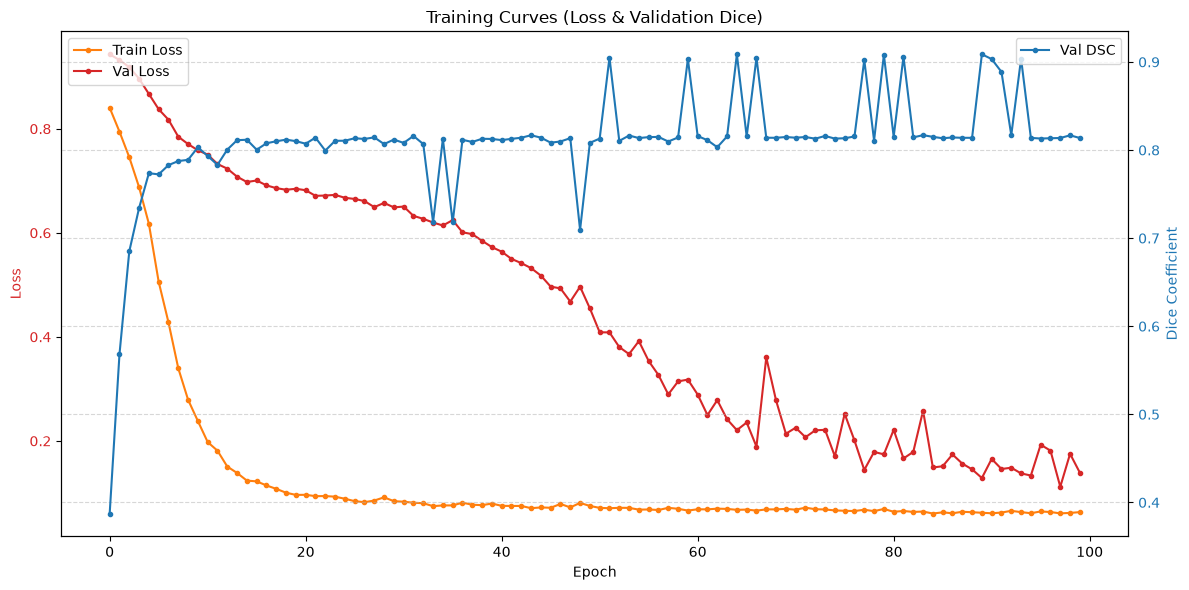

In [2]:
# Note on Training. Refer to the archived source for the detailed original comment.
train_loss_pattern = r'E#(\d+):.*?L=([\d.]+)'
train_matches = re.findall(train_loss_pattern, log_text)
epochs_train = [int(m[0]) for m in train_matches]
train_losses = [float(m[1]) for m in train_matches]

# Note on Validation. Refer to the archived source for the detailed original comment.
val_pattern = r'val loss: ([\d.]+), val dsc: ([\d.]+)'
val_matches = re.findall(val_pattern, log_text)
val_losses = [float(m[0]) for m in val_matches]
val_dscs = [float(m[1]) for m in val_matches]

# Note on Check. Refer to the archived source for the detailed original comment.
assert len(epochs_train) == len(val_losses) == len(val_dscs), "数据长度不一致，请检查解析是否完整"

epochs = epochs_train  # 相同

# Note on Plot. Refer to the archived source for the detailed original comment.
fig, ax1 = plt.subplots(figsize=(12, 6))

# 左轴：损失
color = 'tab:red'
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss', color=color)
ax1.plot(epochs, train_losses, label='Train Loss', color='tab:orange', linestyle='-', marker='.')
ax1.plot(epochs, val_losses, label='Val Loss', color=color, linestyle='-', marker='.')
ax1.tick_params(axis='y', labelcolor=color)
ax1.legend(loc='upper left')

# 右轴：Dice
ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Dice Coefficient', color=color)
ax2.plot(epochs, val_dscs, label='Val DSC', color=color, linestyle='-', marker='.')
ax2.tick_params(axis='y', labelcolor=color)
ax2.legend(loc='upper right')

# 标题和网格
plt.title('Training Curves (Loss & Validation Dice)')
fig.tight_layout()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Note on Save. Refer to the archived source for the detailed original comment.
# plt.savefig('training_curves.png', dpi=300)